# Inversión de forma de onda completa: cycle-skipping y controles negativos

**Nivel 3 — Experimento de investigación** · 60–90 min · propagación de ondas y optimización

## Objetivos
- Leer objetivo acústico Deepwave, parametrización, continuación y evaluación reales del producto.
- Recorrer estados registrados para examinar el efecto de iteraciones.
- Comparar dos valores de regularización con observaciones sintéticas idénticas.
- Inspeccionar el desafío de cycle-skipping, incluido residual retenido de forma de onda.

## Preparación

Ejecute desde la raíz en el entorno fijado:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

La celda experimental imprime las versiones activas.

## Datos
Son artefactos sintéticos **generados por Deepwave** y comprometidos. Los experimentos de iteración y regularización reproducen estados guardados; no inician un solve GPU. El desafío cycle-skipping permanece como control negativo. No son datos de terreno ni prueban que FWI funcione con cualquier entrada.

## Método

La implementación data-pipeline/seismic.py resuelve ecuación acústica escalar 2D con Deepwave, deriva automáticamente el objetivo waveform y actualiza velocidad acotada con L-BFGS y búsqueda fuerte de Wolfe. Usa cuatro mallas de control progresivas y penalización de gradiente físico. El objetivo guardado es aproximadamente

Φ(m)=||P_A B_f(F(m)−d)||²₂ / ||P_A B_f d||²₂ + βR(m)

donde F(m) es el gather simulado, d la observación sintética, P_A selecciona receptores de entrenamiento y B_f es el filtro de fase cero de la etapa de continuación. Los receptores i mod 5 = 2 quedan fuera del objetivo y selección de estados. Puntajes retenidos son diagnósticos posteriores.

Hay cycle-skipping cuando las oscilaciones predichas y observadas están suficientemente desfasadas para que gradientes locales favorezcan alineación/modelo erróneos; más iteraciones no garantizan salir. La continuación de frecuencia puede ampliar la cuenca de atracción, pero el caso desafiado permanece como control negativo. La inspección de estados se guía por historial de entrenamiento; trazas retenidas son diagnóstico únicamente.

La comparación beta usa dos artefactos del mismo modelo estratificado sintético, adquisición, semilla y ruido (β=0.001 frente a β=0.03). El notebook verifica observaciones idénticas. El desafío salino tiene geometría diferente y fuente de 9 Hz: ilustra fallo y no es experimento beta emparejado.

## Estado del arte

Cycle-skipping es una no convexidad central de la inversión waveform. Continuación en frecuencia, parametrización multiescala y regularización pueden mejorar el condicionamiento, pero el éxito depende de banda fuente, modelo inicial, adquisición y ruido. El desafío salino permanece porque la continuación no garantiza recuperación.

### Preguntas
1. ¿Disminuye monótonamente el misfit de entrenamiento? ¿Le sigue el misfit retenido?
2. ¿Qué estructura cambia al subir β: detalle respaldado por datos o suavidad impuesta por el prior?
3. ¿Cumple el desafío salino el criterio declarado? ¿Por qué conservar el control negativo?


### Experimento 3 — seleccione iteración registrada y caso de regularización

Ajuste METHOD y STATE_INDEX para inspeccionar la trayectoria guardada. Las cuatro etapas tienen 28 actualizaciones del optimizador más el estado inicial sin actualizar. La inspección usa solo historial de entrenamiento. BETA_CASE selecciona una de las corridas estratificadas con misma entrada.

In [1]:
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'scipy', 'matplotlib']})
# Reproducible notebook experiment cell.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'data').is_dir() and (p/'data-pipeline').is_dir())
data=root/'data/derived/v2'
def load_case(case_id,variant='reference'):
    return json.loads((data/case_id/f'{variant}.json').read_text(encoding='utf-8'))
layered=load_case('FWI_LAYERED','reference')
strong=load_case('FWI_LAYERED','regularization')
challenge=load_case('FWI_CYCLE_SKIP','reference')
assert layered['observed']==strong['observed'], 'beta comparison must use identical observations'
METHOD='fwi-multiscale'  # also inspect fwi-l2
STATE_INDEX=80           # range 0..115 in stored multistage history
BETA_CASE='reference'    # reference beta=.001; regularization beta=.03
chosen_case=layered if BETA_CASE=='reference' else strong
records=chosen_case['methods'][METHOD]['history_records']
assert 0<=STATE_INDEX<len(records)
selected=records[STATE_INDEX]
print('Engine:',layered['engine'])
print('Synthetic origin:',layered['parameters']['data_origin'],'| stored states:',len(records))
print('Beta values:',layered['parameters']['regularization'],strong['parameters']['regularization'])
print('Identical layered observations:',layered['observed']==strong['observed'])
print('Selected state:',{k:selected[k] for k in ('phase','update','control_grid','cutoff_hz','objective','active_relative_mse','withheld_relative_mse')})
print('Artifact replay only: no solve was run.')
trajectories={
 f"beta={layered['parameters']['regularization']:g}":layered['methods'][METHOD]['history_records'],
 f"beta={strong['parameters']['regularization']:g}":strong['methods'][METHOD]['history_records']}
display(pd.DataFrame([
 {'case':case['id'],'method':METHOD,'beta':case['methods'][METHOD]['solver']['beta'],
  'model_RMSE_ratio':case['methods'][METHOD]['metrics']['model_rmse_ratio'],
  'active_WRMS':case['methods'][METHOD]['metrics']['active_wrms'],
  'withheld_WRMS':case['methods'][METHOD]['metrics']['withheld_wrms'],
  'verdict':case['methods'][METHOD]['evaluation']['status']}
 for case in (layered,strong,challenge)]).round(4))
print('Challenge reason codes:',challenge['methods'][METHOD]['evaluation']['reason_codes'])


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}
Engine: Deepwave 0.0.27 / PyTorch automatic differentiation
Synthetic origin: same-operator synthetic pressure, independent additive Gaussian noise | stored states: 116
Beta values: 0.001 0.03
Identical layered observations: True
Selected state: {'phase': 'spatial-2', 'update': 22, 'control_grid': [17, 24], 'cutoff_hz': 8.0, 'objective': 0.0001239068661, 'active_relative_mse': 0.00114877522, 'withheld_relative_mse': 0.001611977699}
Artifact replay only: no solve was run.


,case,method,beta,model_RMSE_ratio,active_WRMS,withheld_WRMS,verdict
0,FWI_LAYERED,fwi-multiscale,0.001,0.5269,1.2078,1.2330,recovered
1,FWI_LAYERED,fwi-multiscale,0.030,1.7380,2.4982,2.5564,failed
2,FWI_CYCLE_SKIP,fwi-multiscale,0.001,0.8026,1.7506,1.9659,negative-control


Challenge reason codes: ['salt_cycle_skipping_challenge']


### Diagnóstico 2 — trayectoria, efecto del modelo y control negativo

Los gráficos usan estados guardados del solver. Los paneles comparan velocidad final de corridas beta emparejadas y desafío cycle-skipping separado. Se muestra un receptor retenido durante el ajuste como contexto; no selecciona iteración ni ajusta beta.

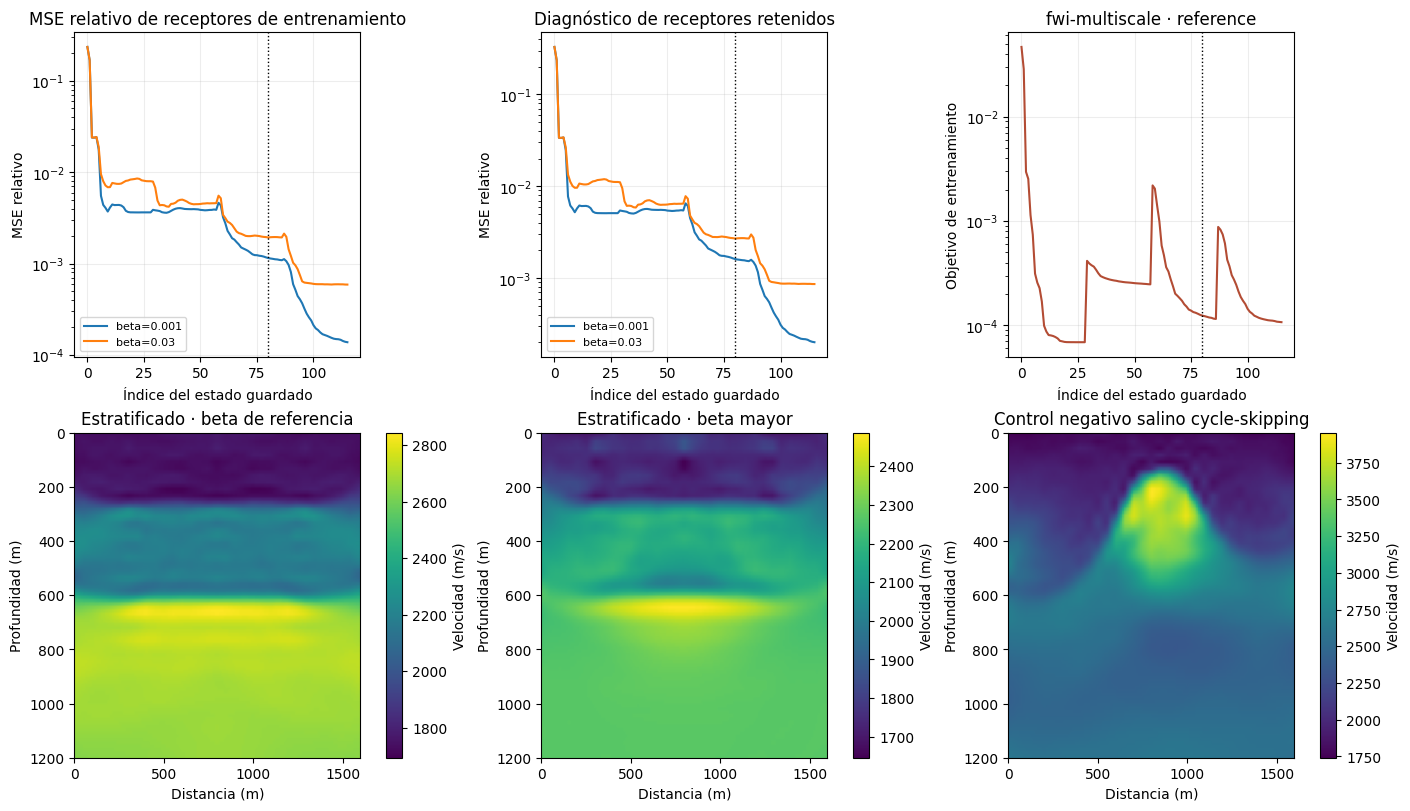

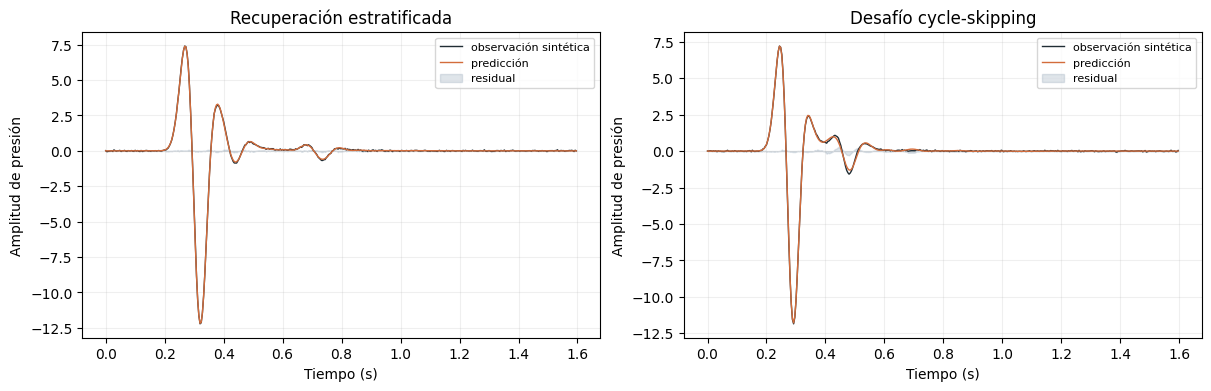

El receptor 12 se excluyó del ajuste; el residual es solo diagnóstico.
Veredicto cycle-skipping conservado: {'status': 'negative-control', 'reason_codes': ['salt_cycle_skipping_challenge'], 'criterion': 'whole-model and active/withheld waveform improve the independent start; active/withheld WRMS <= 2', 'scope': 'synthetic baseline improvement and declared-noise consistency, not exact geology or field validation', 'optimizer_status': 'finite_budget'}


In [2]:
fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
for label,rows in trajectories.items():
    x=np.arange(len(rows))
    axes[0,0].plot(x,[r['active_relative_mse'] for r in rows],label=label)
    axes[0,1].plot(x,[r['withheld_relative_mse'] for r in rows],label=label)
for ax,title in zip(axes[0,:2],['MSE relativo de receptores de entrenamiento','Diagnóstico de receptores retenidos']):
    ax.axvline(STATE_INDEX,color='black',ls=':',lw=1)
    ax.set(xlabel='Índice del estado guardado',ylabel='MSE relativo',title=title)
    ax.set_yscale('log'); ax.grid(alpha=.22); ax.legend(fontsize=8)
axes[0,2].plot(np.arange(len(records)),[r['objective'] for r in records],color='#b34c34')
axes[0,2].axvline(STATE_INDEX,color='black',ls=':',lw=1)
axes[0,2].set(xlabel='Índice del estado guardado',ylabel='Objetivo de entrenamiento',title=f'{METHOD} · {BETA_CASE}')
axes[0,2].set_yscale('log'); axes[0,2].grid(alpha=.22)
for ax,case,title in [(axes[1,0],layered,'Estratificado · beta de referencia'),
                      (axes[1,1],strong,'Estratificado · beta mayor'),
                      (axes[1,2],challenge,'Control negativo salino cycle-skipping')]:
    model=np.asarray(case['methods'][METHOD]['model'])
    im=ax.imshow(model,origin='upper',aspect='auto',
        extent=[0,model.shape[1]*case['grid']['spacing'][1],
                model.shape[0]*case['grid']['spacing'][0],0],cmap='viridis')
    ax.set(title=title,xlabel='Distancia (m)',ylabel='Profundidad (m)')
    plt.colorbar(im,ax=ax,label='Velocidad (m/s)')
plt.show()
# Receiver 12 is withheld because 12 mod 5 equals 2.
shot,receiver=0,12
assert receiver%5==2
time_s=np.arange(len(layered['observed'][shot][receiver]))*layered['dt']
fig,ax=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
for a,case,title in [(ax[0],layered,'Recuperación estratificada'),(ax[1],challenge,'Desafío cycle-skipping')]:
    observed=np.asarray(case['observed'])[shot,receiver]
    predicted=np.asarray(case['methods'][METHOD]['predicted'])[shot,receiver]
    a.plot(time_s,observed,color='#202d34',lw=1,label='observación sintética')
    a.plot(time_s,predicted,color='#d36c3b',lw=1,label='predicción')
    a.fill_between(time_s,observed-predicted,0,color='#7189a0',alpha=.22,label='residual')
    a.set(title=title,xlabel='Tiempo (s)',ylabel='Amplitud de presión')
    a.grid(alpha=.2); a.legend(fontsize=8)
plt.show()
print('El receptor 12 se excluyó del ajuste; el residual es solo diagnóstico.')
print('Veredicto cycle-skipping conservado:',challenge['methods'][METHOD]['evaluation'])


## Resultados

Lea estado seleccionado, tabla beta, historiales, modelos y traza retenida. El veredicto del desafío, incluidos fallos, forma parte del resultado. Aquí no se ejecutó una inversión nueva.

## Resumen
Informe estado seleccionado, betas, comportamiento activo/retenido y veredicto negativo. Distinga replay de una inversa nueva y nombre una prueba necesaria con datos de terreno.

## Referencias
- [Ejemplo FWI acústica Deepwave](https://www.ausargeo.com/deepwave/example_fwi)
- Solver, objetivo, historial y evaluación: data-pipeline/seismic.py
- Artefactos sintéticos: data/derived/v2/FWI_LAYERED/ y data/derived/v2/FWI_CYCLE_SKIP/